# 2026 — Kimi Delta Attention and the Kimi K3 Hybrid

**Papers and models:** Moonshot AI, *"Kimi Linear: An Expressive, Efficient Attention Architecture"* (arXiv 2510.26692, Oct 2025); **Kimi K3** (weights released July 27, 2026) and **Kimi K3.1 Pro** (November 4, 2026). Per Sebastian Raschka's architecture notes, K3's 93-layer backbone is **69 Kimi Delta Attention (KDA) layers + 24 global attention layers**, with **no RoPE anywhere (NoPE)**. K3.1 Pro keeps all 69 KDA layers and makes the 24 global layers sparse with a DeepSeek-style lightning indexer (notebook 75) that selects the top 2,048 tokens per query. Sources disagree on the details: vLLM's day-0 post says the indexer is added to the existing MLA layers, while some model-card summaries describe them as replaced by gated DSA layers.

**KDA** refines Gated DeltaNet (notebook 70). GDN forgets with one **scalar** rate per head; KDA gives **every channel its own forget rate**:

$$\text{GDN:}\quad S_t = \alpha_t\,(I - \beta_t k_t k_t^\top)\, S_{t-1} + \beta_t k_t v_t^\top \qquad\qquad \text{KDA:}\quad S_t = (I - \beta_t k_t k_t^\top)\,\operatorname{Diag}(\alpha_t)\, S_{t-1} + \beta_t k_t v_t^\top$$

with $o_t = S_t^\top q_t$, $S_t \in \mathbb R^{d_k\times d_v}$ and $\alpha_t \in [0,1]^{d_k}$. Some feature dimensions can hold information for a long time while others refresh quickly.

From the paper (Sec. 4): $q, k = \operatorname{L2Norm}(\operatorname{Swish}(\operatorname{ShortConv}(Wx)))$, $v = \operatorname{Swish}(\operatorname{ShortConv}(Wx))$, $\beta = \sigma(W_\beta x)$, $\alpha_t$ from a **low-rank** projection, and output $o = W_o\big(\sigma(W_g^{up}W_g^{down}x) \odot \operatorname{RMSNorm}(\text{KDA})\big)$. Kimi Linear interleaves **3 KDA : 1 full-attention (MLA) layer with NoPE**, since the decaying KDA state already encodes position. That beat full attention on quality (MMLU-Pro 51.0 vs 47.2 at 1.4T tokens; RULER@128k 84.3 vs 81.3), cut the KV cache by up to 75%, and decoded up to 6× faster at 1M tokens.

**Our choice where the paper is not explicit:** the decay function. The paper says it is "similar to GDN and Mamba", so we use $\alpha_t = \exp\!\big(-e^{A}\cdot\operatorname{softplus}(W^{up}_\alpha W^{down}_\alpha x_t + b)\big)$ per channel.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


## 1. The recurrence, and the chunkwise parallel algorithm
A token-by-token loop is slow on GPUs. Kimi Linear processes **chunks** of $C$ tokens with matrix operations (a specialised diagonal-plus-low-rank "WY/UT" form). Deriving it, for one chunk starting from state $S_0$ with cumulative decays $\gamma_t = \prod_{i\le t}\alpha_i$:

- Rewrite the update as $S_t = \operatorname{Diag}(\alpha_t) S_{t-1} + k_t u_t^\top$ with $u_t = \beta_t\,(v_t - S_{t-1}^\top \operatorname{Diag}(\alpha_t) k_t)$.
- Unrolled: $S_t = \operatorname{Diag}(\gamma_t)S_0 + \sum_{i\le t}\operatorname{Diag}(\gamma_t/\gamma_i)\,k_i u_i^\top$.
- With $\tilde K_t = \gamma_t\odot k_t$, $\hat K_i = k_i/\gamma_i$ and $\tilde Q_t = \gamma_t \odot q_t$, all $u$ in the chunk solve one **triangular system**:
$$\big(I + \operatorname{StrictTril}(\operatorname{Diag}(\beta)\tilde K\hat K^\top)\big)\,U = \operatorname{Diag}(\beta)\,(V - \tilde K S_0)$$
- Outputs: $O = \tilde Q S_0 + \operatorname{Tril}(\tilde Q \hat K^\top)\,U$. Next state: $S_C = \operatorname{Diag}(\gamma_C)S_0 + (\gamma_C\odot\hat K)^\top U$.

That is the paper's $M_{[t]}$, $W_{[t]}$, $U_{[t]}$ (Sec. 3.1). **Numerics:** with fast-decaying channels, $\gamma_t$ underflows and $k/\gamma$ overflows. So, like production kernels, we never form $\hat K$ on its own. Every ratio $\gamma_t/\gamma_i$ with $t \ge i$ is computed as $\exp(G_t - G_i)$ with $G = \operatorname{cumsum}(\log\alpha)$, which is always $\le 1$.

In [2]:
def kda_recurrent(q, k, v, alpha, beta):
    """q,k,alpha: (B,H,T,dk)  v: (B,H,T,dv)  beta: (B,H,T). Token-by-token reference."""
    B, H, T, dk = k.shape; S = k.new_zeros(B, H, dk, v.shape[-1]); out = []
    for t in range(T):
        S = alpha[:, :, t, :, None] * S                                                   # Diag(alpha_t) S_{t-1}
        kt = k[:, :, t]
        u = beta[:, :, t, None] * (v[:, :, t] - torch.einsum("bhk,bhkv->bhv", kt, S))     # delta-rule correction
        S = S + kt[..., None] * u[..., None, :]
        out.append(torch.einsum("bhk,bhkv->bhv", q[:, :, t], S))
    return torch.stack(out, 2)

def kda_chunked(q, k, v, log_alpha, beta, C=16):
    """Same result as kda_recurrent, computed chunk by chunk. Decays enter only as exp(G_t - G_i) <= 1 (log space)."""
    B, H, T, dk = k.shape; dv = v.shape[-1]
    S = k.new_zeros(B, H, dk, dv); outs = []
    for s in range(0, T, C):
        qc, kc, vc, lc, bc = (x[:, :, s:s + C] for x in (q, k, v, log_alpha, beta))
        n = kc.shape[2]
        G = torch.cumsum(lc, 2)                                                            # log gamma_t within the chunk
        causal = torch.ones(n, n, dtype=torch.bool, device=k.device).tril()
        Dt = (G[:, :, :, None, :] - G[:, :, None, :, :]).masked_fill(~causal[None, None, :, :, None], float("-inf"))
        E = torch.exp(Dt)                                                                  # gamma_t / gamma_i for i <= t, else 0
        KK = torch.einsum("bhtc,bhic,bhtic->bhti", kc, kc, E)                              # (Kt Kh^T), safely
        QK = torch.einsum("bhtc,bhic,bhtic->bhti", qc, kc, E)                              # (Qt Kh^T), safely
        Kt, Qt = torch.exp(G) * kc, torch.exp(G) * qc
        A = torch.tril(bc[..., None] * KK, -1)
        U = torch.linalg.solve_triangular(torch.eye(n, device=k.device) + A, bc[..., None] * (vc - Kt @ S), upper=False, unitriangular=True)
        outs.append(Qt @ S + QK @ U)
        S = torch.exp(G[:, :, -1, :, None]) * S + (torch.exp(G[:, :, -1:, :] - G) * kc).transpose(-1, -2) @ U
    return torch.cat(outs, 2)

B, H, T, dk, dv = 2, 3, 96, 16, 16
q, k = (F.normalize(torch.randn(B, H, T, dk, device=device), dim=-1) for _ in range(2))
v = torch.randn(B, H, T, dv, device=device)
alpha = torch.exp(-0.3 * torch.rand(B, H, T, dk, device=device))                         # per-channel decays
beta = torch.sigmoid(torch.randn(B, H, T, device=device))
ref, chk = kda_recurrent(q, k, v, alpha, beta), kda_chunked(q, k, v, alpha.log(), beta)
print(f"max |chunked - recurrent| = {(chk - ref).abs().max().item():.2e}")
gdn_alpha = alpha.mean(-1, keepdim=True).expand_as(alpha)                                  # GDN = KDA with one rate per head
print(f"GDN as a special case: max diff {(kda_chunked(q, k, v, gdn_alpha.log(), beta) - kda_recurrent(q, k, v, gdn_alpha, beta)).abs().max().item():.2e}")
strong = torch.exp(-8 * torch.rand(B, H, T, dk, device=device))                         # very fast decays: gamma underflows over a chunk
print(f"very fast decays: max diff {(kda_chunked(q, k, v, strong.log(), beta) - kda_recurrent(q, k, v, strong, beta)).abs().max().item():.2e} (log-space keeps it exact)")

def timeit(fn, reps=3):
    fn(); t0 = time.time()
    for _ in range(reps): fn()
    return (time.time() - t0) / reps * 1000
Tl = 512; ql, kl = (F.normalize(torch.randn(4, 4, Tl, 32, device=device), dim=-1) for _ in range(2))
vl = torch.randn(4, 4, Tl, 32, device=device); al = torch.exp(-0.05 * torch.rand(4, 4, Tl, 32, device=device)); bl = torch.rand(4, 4, Tl, device=device)
print(f"T={Tl}: recurrent {timeit(lambda: kda_recurrent(ql, kl, vl, al, bl)):.0f} ms | chunked (C=16) {timeit(lambda: kda_chunked(ql, kl, vl, al.log(), bl)):.0f} ms")

max |chunked - recurrent| = 2.38e-07
GDN as a special case: max diff 2.38e-07
very fast decays: max diff 1.22e-06 (log-space keeps it exact)


T=512: recurrent 74 ms | chunked (C=16) 16 ms


## 2. The KDA layer

In [3]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6): super().__init__(); self.w = nn.Parameter(torch.ones(d)); self.eps = eps
    def forward(self, x): return self.w * x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)

class ShortConv(nn.Module):
    def __init__(self, d, k=4): super().__init__(); self.c = nn.Conv1d(d, d, k, groups=d, padding=k - 1)
    def forward(self, x): return self.c(x.transpose(1, 2))[..., : x.shape[1]].transpose(1, 2)

class KDALayer(nn.Module):
    """channelwise=True: KDA. channelwise=False: Gated DeltaNet (one decay rate per head), otherwise identical."""
    def __init__(self, d, heads=2, channelwise=True, rank=None):
        super().__init__()
        self.h, self.dk, self.cw = heads, d // heads, channelwise
        self.wq, self.wk, self.wv = (nn.Linear(d, d, bias=False) for _ in range(3))
        self.cq, self.ck, self.cv = ShortConv(d), ShortConv(d), ShortConv(d)
        self.w_beta = nn.Linear(d, heads)
        r = rank or self.dk                                                                # paper: rank = head dimension
        out_a = d if channelwise else heads
        self.a_down, self.a_up = nn.Linear(d, r, bias=False), nn.Linear(r, out_a, bias=True)
        self.A_log = nn.Parameter(torch.log(torch.empty(out_a).uniform_(1, 16)))            # Mamba-style decay rates
        with torch.no_grad(): self.a_up.bias.copy_(torch.log(torch.expm1(torch.empty(out_a).uniform_(1e-3, 0.1))))   # softplus^-1(dt)
        self.g_down, self.g_up = nn.Linear(d, r, bias=False), nn.Linear(r, d, bias=False)    # low-rank sigmoid output gate
        self.onorm, self.wo = RMSNorm(self.dk), nn.Linear(d, d, bias=False)
    def forward(self, x, C=16):
        B, T, D = x.shape
        sh = lambda t: t.view(B, T, self.h, self.dk).transpose(1, 2)                       # -> (B, H, T, dk)
        q = F.normalize(F.silu(sh(self.cq(self.wq(x)))), dim=-1)
        k = F.normalize(F.silu(sh(self.ck(self.wk(x)))), dim=-1)
        v = F.silu(sh(self.cv(self.wv(x))))
        beta = torch.sigmoid(self.w_beta(x)).transpose(1, 2)                               # (B, H, T)
        log_a = -torch.exp(self.A_log) * F.softplus(self.a_up(self.a_down(x)))             # log alpha <= 0
        log_alpha = (log_a.view(B, T, self.h, self.dk).transpose(1, 2) if self.cw
                     else log_a.transpose(1, 2)[..., None].expand(B, self.h, T, self.dk))
        o = kda_chunked(q, k, v, log_alpha, beta, C)
        o = self.onorm(o).transpose(1, 2).reshape(B, T, D)
        return self.wo(torch.sigmoid(self.g_up(self.g_down(x))) * o)

class GlobalAttention(nn.Module):
    """Full causal attention with a sigmoid output gate. rope=False is NoPE, as in Kimi Linear / K3."""
    def __init__(self, d, heads=4, rope=False):
        super().__init__(); self.h, self.dh, self.rope = heads, d // heads, rope
        self.qkv, self.gate, self.o = nn.Linear(d, 3 * d, bias=False), nn.Linear(d, d), nn.Linear(d, d, bias=False)
    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(x).view(B, T, 3, self.h, self.dh).permute(2, 0, 3, 1, 4)
        if self.rope:
            inv = 1.0 / 10000 ** (torch.arange(0, self.dh, 2, device=x.device).float() / self.dh)
            ang = torch.arange(T, device=x.device).float()[:, None] * inv
            rot = lambda t: torch.stack([t[..., ::2] * ang.cos() - t[..., 1::2] * ang.sin(), t[..., ::2] * ang.sin() + t[..., 1::2] * ang.cos()], -1).flatten(-2)
            q, k = rot(q), rot(k)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True).transpose(1, 2).reshape(B, T, D)
        return self.o(y * torch.sigmoid(self.gate(x)))

class Model(nn.Module):
    def __init__(self, layers, V, d=64):
        super().__init__()
        self.emb = nn.Embedding(V, d)                                                       # no position embedding anywhere
        self.mix = nn.ModuleList(layers)
        self.mlps = nn.ModuleList([nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d)) for _ in layers])
        self.n1 = nn.ModuleList([RMSNorm(d) for _ in layers]); self.n2 = nn.ModuleList([RMSNorm(d) for _ in layers])
        self.head = nn.Linear(d, V)
    def forward(self, x):
        h = self.emb(x)
        for m, f, n1, n2 in zip(self.mix, self.mlps, self.n1, self.n2): h = h + m(n1(h)); h = h + f(n2(h))
        return self.head(h)

def train_eval(make, batch_fn, positions, steps=800, lr=3e-3, B=64):
    seed_everything(0); m = make().to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=steps, pct_start=0.1); t0 = time.time()
    for s in range(steps):
        x, y = batch_fn(B); logits = m(x)[:, positions]
        loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), y.reshape(-1))
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step(); sched.step()
    m.eval()
    with torch.no_grad():
        x, y = batch_fn(1000); acc = (m(x)[:, positions].argmax(-1) == y).float().mean().item()
    return acc, time.time() - t0

## 3. NoPE works because KDA carries position
Task: **lag-copy**. At every position output the token from exactly 7 steps earlier. This needs to know *where* tokens are. Attention without any position encoding (NoPE) has only the causal mask to go on. Put one KDA layer underneath (K3's layout, in miniature) and its decaying, convolved state supplies the positional signal.

In [4]:
LAG, Tlag, Vlag = 7, 64, 16
def lag_batch(B):
    x = torch.randint(0, Vlag, (B, Tlag), device=device); return x, x[:, :-LAG]
lag_pos = torch.arange(LAG, Tlag, device=device)
d = 64
for name, make in [("NoPE attention only (2 layers)", lambda: Model([GlobalAttention(d), GlobalAttention(d)], Vlag)),
                   ("RoPE attention only (2 layers)", lambda: Model([GlobalAttention(d, rope=True), GlobalAttention(d, rope=True)], Vlag)),
                   ("KDA + NoPE attention (K3-style)", lambda: Model([KDALayer(d), GlobalAttention(d)], Vlag))]:
    acc, sec = train_eval(make, lag_batch, lag_pos, steps=600)
    print(f"{name:34s} lag-{LAG} copy accuracy {acc:.3f}   ({sec:.0f}s)")

NoPE attention only (2 layers)     lag-7 copy accuracy 0.183   (12s)


RoPE attention only (2 layers)     lag-7 copy accuracy 1.000   (17s)


KDA + NoPE attention (K3-style)    lag-7 copy accuracy 0.973   (78s)


## 4. KDA vs. Gated DeltaNet: recall with overwrites
The task from notebook 70: 16 key–value writes using 6 keys (so keys get re-bound), then queries for the **latest** value of each key. Same layer except the decay granularity: one rate per head (GDN) or one per channel (KDA). Both are followed by one NoPE attention layer, as in the hybrid. Expect both to solve this small task. The paper's quality gap (e.g. MMLU-Pro 51.0 vs 47.9, RULER@128k 84.3 vs 80.5) appeared at 48B parameters and 1.4T tokens; here we check that the extra flexibility costs nothing and then look at what it learns.

In [5]:
NK, NV, W, Q = 32, 32, 16, 6
Vrec = NK + NV + 1
def rec_batch(B):
    key_set = torch.rand(B, NK).argsort(1)[:, :Q]
    wk = key_set.gather(1, torch.randint(0, Q, (B, W))); wk[:, :Q] = key_set; wk = wk.gather(1, torch.rand(B, W).argsort(1))
    wv = torch.randint(NK, NK + NV, (B, W)); last = torch.zeros(B, NK, dtype=torch.long)
    for t in range(W): last[torch.arange(B), wk[:, t]] = wv[:, t]
    qk = key_set.gather(1, torch.rand(B, Q).argsort(1)); target = last.gather(1, qk)
    x = torch.cat([torch.stack([wk, wv], 2).view(B, 2 * W), torch.stack([qk, torch.full((B, Q), Vrec - 1)], 2).view(B, 2 * Q)], 1)
    return x.to(device), target.to(device)
rec_pos = torch.arange(2 * W, 2 * W + 2 * Q, 2, device=device)
for name, make in [("Gated DeltaNet (scalar decay) + NoPE attn", lambda: Model([KDALayer(d, channelwise=False), GlobalAttention(d)], Vrec)),
                   ("KDA (channel-wise decay)     + NoPE attn", lambda: Model([KDALayer(d, channelwise=True), GlobalAttention(d)], Vrec))]:
    acc, sec = train_eval(make, rec_batch, rec_pos, steps=600)
    print(f"{name}: recall accuracy {acc:.3f}   ({sec:.0f}s)")

Gated DeltaNet (scalar decay) + NoPE attn: recall accuracy 0.999   (61s)


KDA (channel-wise decay)     + NoPE attn: recall accuracy 0.999   (61s)


## 5. What did the channel-wise gates learn?
Per-channel decay rates spread out: some channels keep information for hundreds of steps (α close to 1), others forget within a few (lower α). One scalar per head can't do both.

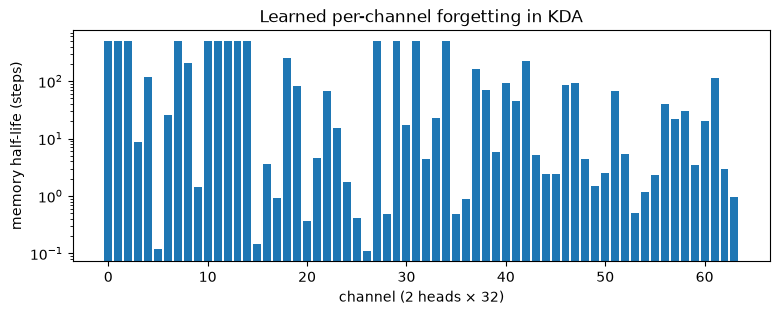

half-life across channels: min 0.1, median 20.5, max 116563 steps


In [6]:
seed_everything(0)
m = Model([KDALayer(d), GlobalAttention(d)], Vrec).to(device)
opt = torch.optim.AdamW(m.parameters(), lr=3e-3)
for _ in range(300):
    x, y = rec_batch(64); loss = F.cross_entropy(m(x)[:, rec_pos].reshape(-1, Vrec), y.reshape(-1)); opt.zero_grad(); loss.backward(); opt.step()
kda = m.mix[0]; x, _ = rec_batch(256)
with torch.no_grad():
    h = m.n1[0](m.emb(x)); log_a = -torch.exp(kda.A_log) * F.softplus(kda.a_up(kda.a_down(h)))
    half_life = (math.log(0.5) / log_a.clamp(max=-1e-6)).mean((0, 1)).cpu()                 # steps until a channel's memory halves
plt.figure(figsize=(9, 3)); plt.bar(range(d), half_life.clamp(max=500)); plt.yscale("log")
plt.xlabel("channel (2 heads × 32)"); plt.ylabel("memory half-life (steps)"); plt.title("Learned per-channel forgetting in KDA"); plt.show()
print(f"half-life across channels: min {half_life.min():.1f}, median {half_life.median():.1f}, max {half_life.max():.0f} steps")

## Where K3 fits
- **K3 (July 2026):** 69 KDA + 24 gated-MLA layers, NoPE everywhere. KDA layers keep a fixed-size state, so most of the network has no growing KV cache.
- **K3.1 Pro (November 2026):** same 69 KDA layers; the 24 global layers get a **DeepSeek Sparse Attention** indexer, so even the global layers read only ~2,048 selected positions per query (notebooks 75, 86). The model has 2.8T total parameters, 104B active, and a 1M-token context. The design converges with DeepSeek-V4 (notebook 78) and Qwen3.5 (notebook 79): **mostly linear-memory layers, a few sparse global layers, a sparse MoE**.
- Caveats: the K3/K3.1 layer counts and NoPE choice come from Raschka's architecture notes, not a primary technical report; the exact $\alpha_t$ parameterisation is ours (Mamba/GDN style, as the paper describes). Toy tasks show the mechanisms, not the paper's scale results.